# Практичне завдання 2: Логістична регресія та федеративне навчання

**Датасет:** Dry Bean Dataset (UCI / Kaggle) — 13 611 зерен, 16 числових ознак, 7 сортів (`Class`).

**Мета:** зрозуміти архітектуру багатокласової логістичної регресії (softmax), самостійно реалізувати модель засобами `numpy`, змоделювати федеративне навчання (FedAvg), коректно розподілити дані між клієнтами та сервером і дослідити ефекти Non-IID та кількості локальних епох.

**Структура ноутбука** повторює методичку (Етапи 1–6 + опційні елементи + теоретичні відповіді).


## Імпорт бібліотек


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    log_loss,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (8, 4.5)


## Етап 1. Дослідження даних та попередня обробка

### Обґрунтування вибору датасету

Dry Bean Dataset підходить для федеративного навчання, бо:
1. **багатокласова** задача (7 сортів) — перевіряємо softmax і метрики з дисбалансом;
2. **достатньо прикладів** (~13.6k), щоб розподілити між кількома клієнтами без надто малих локальних вибірок;
3. усі ознаки **числові** — фокус на моделі та FedAvg, а не на складному кодуванні категорій;
4. класи **нерівномірні** (від ~354 до ~3546) — реалістичний сценарій для balanced accuracy / macro-F1.


### 1.1. Завантаження даних та первинний аналіз


In [2]:
df = pd.read_csv('dry_bean.csv')
print('Розмір датасету:', df.shape)
df.head()


Розмір датасету: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [3]:
df.info()
print('\nПропущені значення (сума по стовпцях):')
print(df.isnull().sum().sort_values(ascending=False).head(10))
print('\nДублікати рядків:', df.duplicated().sum())


<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Частки класів:
Class
DERMASON    26.05
SIRA        19.37
SEKER       14.89
HOROZ       14.17
CALI        11.98
BARBUNYA     9.71
BOMBAY       3.84
Name: proportion, dtype: float64


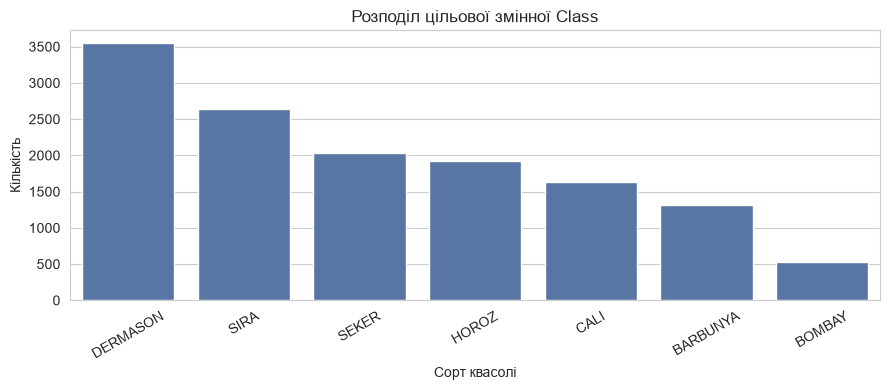

In [4]:
TARGET = 'Class'
print(df[TARGET].value_counts())
print('\nЧастки класів:')
print((df[TARGET].value_counts(normalize=True) * 100).round(2))

fig, ax = plt.subplots(figsize=(9, 4))
order = df[TARGET].value_counts().index
sns.countplot(data=df, x=TARGET, order=order, ax=ax, color='#4C72B0')
ax.set_title('Розподіл цільової змінної Class')
ax.set_xlabel('Сорт квасолі')
ax.set_ylabel('Кількість')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [5]:
feature_cols = [c for c in df.columns if c != TARGET]
df[feature_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


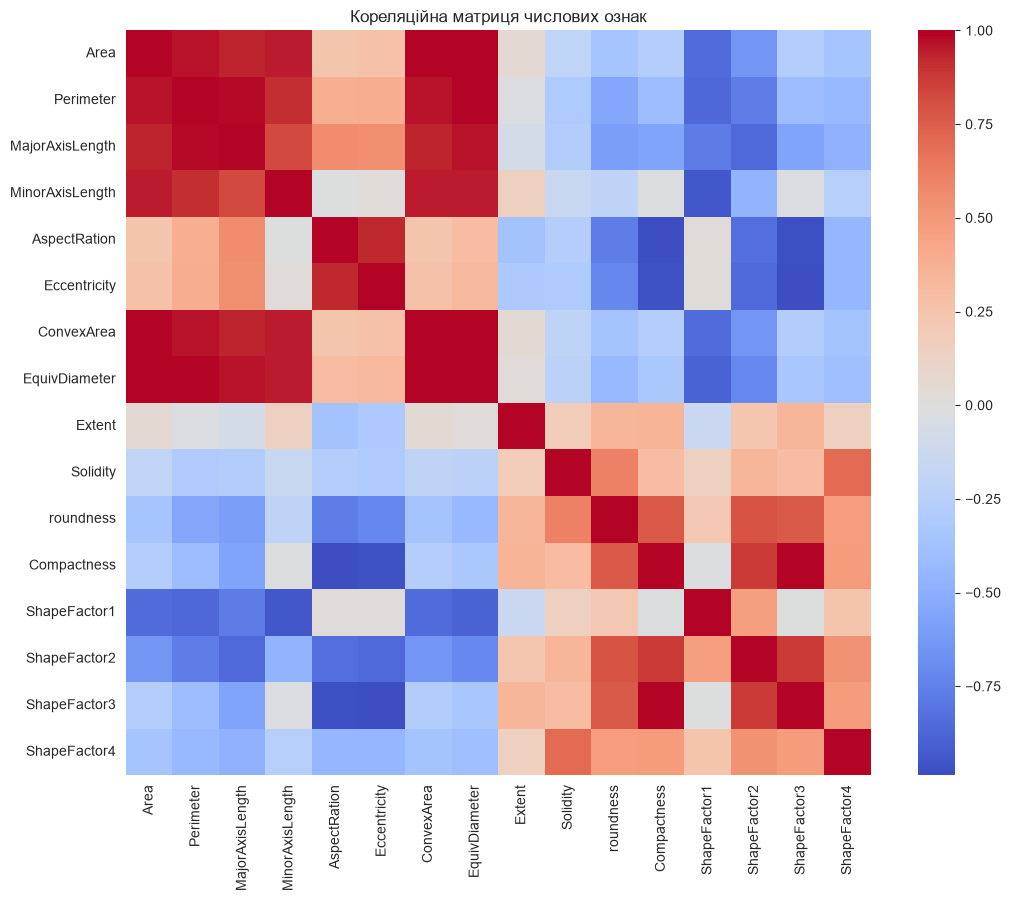

TOP-10 пар ознак за |кореляцією|:
Area          ConvexArea         0.999939
Compactness   ShapeFactor3       0.998686
Perimeter     EquivDiameter      0.991380
AspectRation  Compactness        0.987687
ConvexArea    EquivDiameter      0.985226
Area          EquivDiameter      0.984968
Eccentricity  ShapeFactor3       0.981058
AspectRation  ShapeFactor3       0.978592
Perimeter     MajorAxisLength    0.977338
Eccentricity  Compactness        0.970313
dtype: float64


In [6]:
corr = df[feature_cols].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap='coolwarm', center=0, ax=ax, square=True)
ax.set_title('Кореляційна матриця числових ознак')
plt.tight_layout()
plt.show()

# Пари з найсильнішою |кореляцією|
pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    .stack()
    .abs()
    .sort_values(ascending=False)
)
print('TOP-10 пар ознак за |кореляцією|:')
print(pairs.head(10))


**Спостереження EDA:**
- 13 611 об'єктів, 16 числових ознак + `Class` (7 категорій).
- Пропусків немає; є кілька дублікатів — приберемо їх перед розбиттям.
- Класи незбалансовані: `DERMASON` найбільший, `BOMBAY` найменший.
- Сильна мультиколінеарність (наприклад, `Area`–`ConvexArea`, `Compactness`–`ShapeFactor3`) — для лінійної моделі це очікувано; Ridge допоможе стабілізувати ваги.


### 1.2. Розбиття вибірки — ДО відбору ознак і масштабування

Схема (стратифіковано за `Class`):
1. **Global Test** — 20% (лише фінальна оцінка на сервері);
2. з решти: **Global Validation** — 15% (~12% від усіх даних);
3. **FL Train Pool** — решта (~68%), далі розподіляється між клієнтами.

**Питання методички: чому розбиття до масштабування / кодування? Що таке Data Leakage?**

Якщо обчислити `mean`/`std` (або будь-які статистики кодування) на всьому датасеті, інформація з validation/test «просочується» у тренування. Це і є **Data Leakage**: модель отримує непряму інформацію про дані, на яких її оцінюватимуть, і метрики стають завищеними. Тому спочатку ділимо, потім fit scaler лише на train (або на FL Train Pool у спрощеній FL-симуляції).


In [7]:
# Прибираємо дублікати до розбиття
df = df.drop_duplicates().reset_index(drop=True)
print('Після видалення дублікатів:', df.shape)

X_all = df[feature_cols].copy()
y_all = df[TARGET].copy()

# 1) Global Test = 20%
X_temp, X_test, y_temp, y_test = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=RANDOM_STATE
)

# 2) Global Validation ≈ 15% від temp → ~12% від усіх
X_fl, X_val, y_fl, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15, stratify=y_temp, random_state=RANDOM_STATE
)

print(f'Global Test:      {len(X_test):5d} ({100 * len(X_test) / len(df):.1f}%)')
print(f'Global Validation:{len(X_val):5d} ({100 * len(X_val) / len(df):.1f}%)')
print(f'FL Train Pool:    {len(X_fl):5d} ({100 * len(X_fl) / len(df):.1f}%)')


Після видалення дублікатів: (13543, 17)
Global Test:       2709 (20.0%)
Global Validation: 1626 (12.0%)
FL Train Pool:     9208 (68.0%)


### 1.3. Відбір ознак

Відбір виконуємо **лише на FL Train Pool** (без test/val). Усі 16 ознак — фізичні характеристики зерна; приберемо лише майже дубльовані за кореляцією з іншими, щоб зменшити мультиколінеарність, зберігаючи інформативність.


In [8]:
# Кореляції лише на FL Train Pool
corr_fl = X_fl.corr().abs()
upper = corr_fl.where(np.triu(np.ones(corr_fl.shape), k=1).astype(bool))

# Кандидати на видалення: кореляція > 0.98 з іншою ознакою
to_drop = [col for col in upper.columns if any(upper[col] > 0.98)]
print('Ознаки з |corr| > 0.98 щодо вже обраних (кандидати):', to_drop)

SELECTED = [c for c in feature_cols if c not in set(to_drop)]
# Якщо поріг нічого не відсіяв — прибираємо відомі майже-дублікати вручну
if len(SELECTED) == len(feature_cols):
    SELECTED = [c for c in feature_cols if c not in {'ConvexArea', 'ShapeFactor3'}]
print('Обрані ознаки (%d):' % len(SELECTED))
print(SELECTED)

X_fl = X_fl[SELECTED]
X_val = X_val[SELECTED]
X_test = X_test[SELECTED]


Ознаки з |corr| > 0.98 щодо вже обраних (кандидати): ['ConvexArea', 'EquivDiameter', 'Compactness', 'ShapeFactor3']
Обрані ознаки (12):
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'Extent', 'Solidity', 'roundness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor4']


### 1.4. Кодування цільової змінної

Категоріальних **ознак** немає. Ціль `Class` кодуємо як цілі мітки `0..C-1` (`LabelEncoder`) і далі в one-hot для softmax / cross-entropy. One-Hot для ознак не потрібен; Ordinal/Target Encoding для ознак тут не застосовуємо.


In [9]:
label_encoder = LabelEncoder()
y_fl_enc = label_encoder.fit_transform(y_fl)
y_val_enc = label_encoder.transform(y_val)
y_test_enc = label_encoder.transform(y_test)
CLASS_NAMES = list(label_encoder.classes_)
N_CLASSES = len(CLASS_NAMES)
print('Класи:', CLASS_NAMES)


def to_one_hot(y: np.ndarray, n_classes: int = N_CLASSES) -> np.ndarray:
    Y = np.zeros((len(y), n_classes), dtype=float)
    Y[np.arange(len(y)), y] = 1.0
    return Y


Y_fl = to_one_hot(y_fl_enc)
Y_val = to_one_hot(y_val_enc)
Y_test = to_one_hot(y_test_enc)


Класи: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


### 1.5. Масштабування

**Спрощений федеративний підхід (згідно з методичкою):** scaler навчається на всьому **FL Train Pool** до розподілу між клієнтами. Це частина симуляції. Test/val не беруть участь у fit.

Альтернатива «більш федеративна» (локальні mean/var → зважена агрегація на сервері) коротко згадана нижче в тексті; у коді використовуємо спрощений варіант для відтворюваності експериментів.


In [10]:
scaler = StandardScaler()
X_fl_s = scaler.fit_transform(X_fl)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

print('FL Train mean≈0:', np.abs(X_fl_s.mean(axis=0)).max() < 1e-8)
print('FL Train std≈1:', np.allclose(X_fl_s.std(axis=0, ddof=0), 1.0, atol=1e-6))


FL Train mean≈0: True
FL Train std≈1: True


## Етап 2. Реалізація багатокласової логістичної регресії (numpy)

Модель: $Z = XW + b$, $P = \mathrm{softmax}(Z)$, loss = cross-entropy (+ Ridge на $W$).

Softmax зі стабілізацією: віднімаємо $\max$ по рядку перед `exp`.
Цикли по прикладах для loss/градієнтів **заборонені** — лише векторизація.


In [11]:
class SoftmaxLogisticRegression:
    """Багатокласова логістична регресія (softmax) на numpy."""

    def __init__(self, n_features: int, n_classes: int, l2: float = 0.0, seed: int = 42):
        rng = np.random.default_rng(seed)
        # невелика ініціалізація для стабільності softmax
        self.W = rng.normal(0.0, 0.01, size=(n_features, n_classes))
        self.b = np.zeros((1, n_classes))
        self.l2 = float(l2)
        self.history_ = {'train_loss': [], 'val_loss': [], 'val_acc': []}

    @staticmethod
    def softmax(Z: np.ndarray) -> np.ndarray:
        Z_shift = Z - Z.max(axis=1, keepdims=True)
        exp_Z = np.exp(Z_shift)
        return exp_Z / exp_Z.sum(axis=1, keepdims=True)

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        return self.softmax(X @ self.W + self.b)

    def predict(self, X: np.ndarray) -> np.ndarray:
        return np.argmax(self.predict_proba(X), axis=1)

    def loss(self, X: np.ndarray, Y: np.ndarray) -> float:
        P = self.predict_proba(X)
        eps = 1e-12
        ce = -np.mean(np.sum(Y * np.log(P + eps), axis=1))
        reg = 0.5 * self.l2 * np.sum(self.W ** 2)
        return float(ce + reg)

    def gradients(self, X: np.ndarray, Y: np.ndarray):
        m = X.shape[0]
        P = self.predict_proba(X)
        dW = (X.T @ (P - Y)) / m + self.l2 * self.W
        db = np.mean(P - Y, axis=0, keepdims=True)
        return dW, db

    def _minibatches(self, X, Y, batch_size, rng):
        n = X.shape[0]
        idx = rng.permutation(n)
        for start in range(0, n, batch_size):
            b = idx[start:start + batch_size]
            yield X[b], Y[b]

    def fit(
        self,
        X: np.ndarray,
        Y: np.ndarray,
        X_val: np.ndarray | None = None,
        Y_val: np.ndarray | None = None,
        lr: float = 0.1,
        batch_size: int = 128,
        epochs: int = 50,
        seed: int = 42,
        verbose: bool = False,
        record_every: int = 1,
    ):
        self.history_ = {'train_loss': [], 'val_loss': [], 'val_acc': []}
        rng = np.random.default_rng(seed)
        y_val_labels = None if Y_val is None else np.argmax(Y_val, axis=1)

        for epoch in range(1, epochs + 1):
            for Xb, Yb in self._minibatches(X, Y, batch_size, rng):
                dW, db = self.gradients(Xb, Yb)
                self.W -= lr * dW
                self.b -= lr * db

            if epoch % record_every == 0 or epoch == epochs:
                tr_loss = self.loss(X, Y)
                self.history_['train_loss'].append(tr_loss)
                if X_val is not None and Y_val is not None:
                    va_loss = self.loss(X_val, Y_val)
                    va_acc = float(np.mean(self.predict(X_val) == y_val_labels))
                    self.history_['val_loss'].append(va_loss)
                    self.history_['val_acc'].append(va_acc)
                    if verbose and (epoch % max(1, epochs // 5) == 0 or epoch == epochs):
                        print(f'epoch {epoch:3d} | train_loss={tr_loss:.4f} | val_loss={va_loss:.4f} | val_acc={va_acc:.4f}')
                elif verbose and (epoch % max(1, epochs // 5) == 0 or epoch == epochs):
                    print(f'epoch {epoch:3d} | train_loss={tr_loss:.4f}')
        return self

    def get_params(self):
        return self.W.copy(), self.b.copy()

    def set_params(self, W, b):
        self.W = W.copy()
        self.b = b.copy()
        return self


def evaluate_model(model, X, y_true, class_names=CLASS_NAMES, title=None, plot_cm=False):
    proba = model.predict_proba(X)
    pred = np.argmax(proba, axis=1)
    metrics = {
        'accuracy': accuracy_score(y_true, pred),
        'macro_f1': f1_score(y_true, pred, average='macro'),
        'balanced_accuracy': balanced_accuracy_score(y_true, pred),
        'log_loss': log_loss(y_true, proba, labels=list(range(len(class_names)))),
    }
    if plot_cm:
        fig, ax = plt.subplots(figsize=(7, 6))
        ConfusionMatrixDisplay(
            confusion_matrix(y_true, pred), display_labels=class_names
        ).plot(ax=ax, cmap='Blues', colorbar=False, xticks_rotation=45)
        ax.set_title(title or 'Confusion Matrix')
        plt.tight_layout()
        plt.show()
    return metrics


def print_metrics(name, metrics):
    print(f"{name}:")
    for k, v in metrics.items():
        print(f'  {k:20s} = {v:.4f}')


## Етап 3. Центрально навчена базова модель

Підбираємо `lr`, `batch_size`, `l2` за **Global Validation**; фінальну оцінку — лише на **Global Test**.


In [12]:
from itertools import product

param_grid = {
    'lr': [0.05, 0.1, 0.3],
    'batch_size': [64, 128],
    'l2': [0.0, 1e-4, 1e-3],
}

results = []
for lr, bs, l2 in product(param_grid['lr'], param_grid['batch_size'], param_grid['l2']):
    model = SoftmaxLogisticRegression(
        n_features=X_fl_s.shape[1], n_classes=N_CLASSES, l2=l2, seed=RANDOM_STATE
    )
    model.fit(
        X_fl_s, Y_fl, X_val_s, Y_val,
        lr=lr, batch_size=bs, epochs=40, seed=RANDOM_STATE, verbose=False
    )
    m = evaluate_model(model, X_val_s, y_val_enc, plot_cm=False)
    results.append({'lr': lr, 'batch_size': bs, 'l2': l2, **m})

results_df = pd.DataFrame(results).sort_values('macro_f1', ascending=False)
print('TOP-5 конфігурацій за macro-F1 на Global Validation:')
display(results_df.head(5))

best = results_df.iloc[0]
BEST_LR = float(best['lr'])
BEST_BS = int(best['batch_size'])
BEST_L2 = float(best['l2'])
print(f'\nОбрано: lr={BEST_LR}, batch_size={BEST_BS}, l2={BEST_L2}')


TOP-5 конфігурацій за macro-F1 на Global Validation:


,lr,batch_size,l2,accuracy,macro_f1,balanced_accuracy,log_loss
6,0.1,64,0.0000,0.942189,0.952574,0.951699,0.192386
7,0.1,64,0.0001,0.942189,0.952574,0.951699,0.193791
16,0.3,128,0.0001,0.941574,0.952194,0.951364,0.189293
15,0.3,128,0.0000,0.941574,0.952194,0.951364,0.187716
17,0.3,128,0.0010,0.940344,0.951045,0.950042,0.205394



Обрано: lr=0.1, batch_size=64, l2=0.0


epoch  16 | train_loss=0.2424 | val_loss=0.2129 | val_acc=0.9379
epoch  32 | train_loss=0.2277 | val_loss=0.1958 | val_acc=0.9422
epoch  48 | train_loss=0.2230 | val_loss=0.1905 | val_acc=0.9422


epoch  64 | train_loss=0.2207 | val_loss=0.1873 | val_acc=0.9422


epoch  80 | train_loss=0.2193 | val_loss=0.1856 | val_acc=0.9403


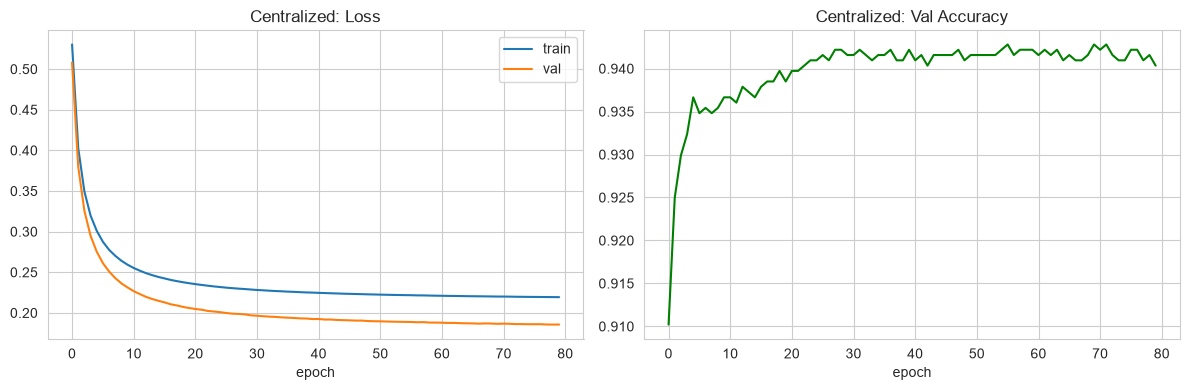

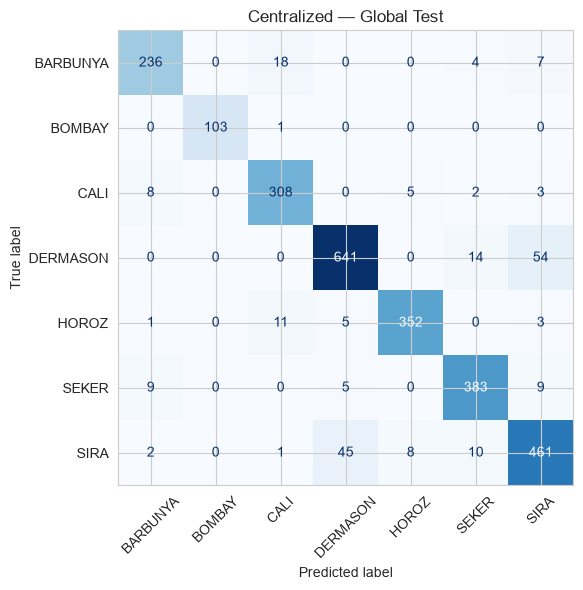

Centralized @ Validation:
  accuracy             = 0.9403
  macro_f1             = 0.9507
  balanced_accuracy    = 0.9495
  log_loss             = 0.1856
Centralized @ Global Test:
  accuracy             = 0.9169
  macro_f1             = 0.9281
  balanced_accuracy    = 0.9277
  log_loss             = 0.2244


In [13]:
central_model = SoftmaxLogisticRegression(
    n_features=X_fl_s.shape[1], n_classes=N_CLASSES, l2=BEST_L2, seed=RANDOM_STATE
)
central_model.fit(
    X_fl_s, Y_fl, X_val_s, Y_val,
    lr=BEST_LR, batch_size=BEST_BS, epochs=80, seed=RANDOM_STATE, verbose=True
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(central_model.history_['train_loss'], label='train')
axes[0].plot(central_model.history_['val_loss'], label='val')
axes[0].set_title('Centralized: Loss')
axes[0].set_xlabel('epoch')
axes[0].legend()
axes[1].plot(central_model.history_['val_acc'], color='green')
axes[1].set_title('Centralized: Val Accuracy')
axes[1].set_xlabel('epoch')
plt.tight_layout()
plt.show()

central_val = evaluate_model(central_model, X_val_s, y_val_enc)
central_test = evaluate_model(
    central_model, X_test_s, y_test_enc,
    title='Centralized — Global Test', plot_cm=True
)
print_metrics('Centralized @ Validation', central_val)
print_metrics('Centralized @ Global Test', central_test)


**Висновок (централізована модель):** loss спадає, validation accuracy стабілізується. Ridge (`l2`) зменшує перенавчання при мультиколінеарних ознаках. Ця модель — верхня межа якості при повному доступі до FL Train Pool.


## Етап 4. Розподіл даних між клієнтами та сервером

### Архітектура
- **Сервер:** Global Test, Global Validation, агреговані ваги. **Немає** сирих даних клієнтів.
- **Клієнт $k$:** лише локальна вибірка $D_k$ (і опційно локальна val з $D_k$). Немає доступу до Global Test/Val та даних інших клієнтів.

### Типи розподілу
1. **IID** — стратифіковані приблизно рівні частки.
2. **Non-IID (Dirichlet($\alpha$))** — для кожного класу пропорції між клієнтами ~ Dirichlet.


=== IID ===


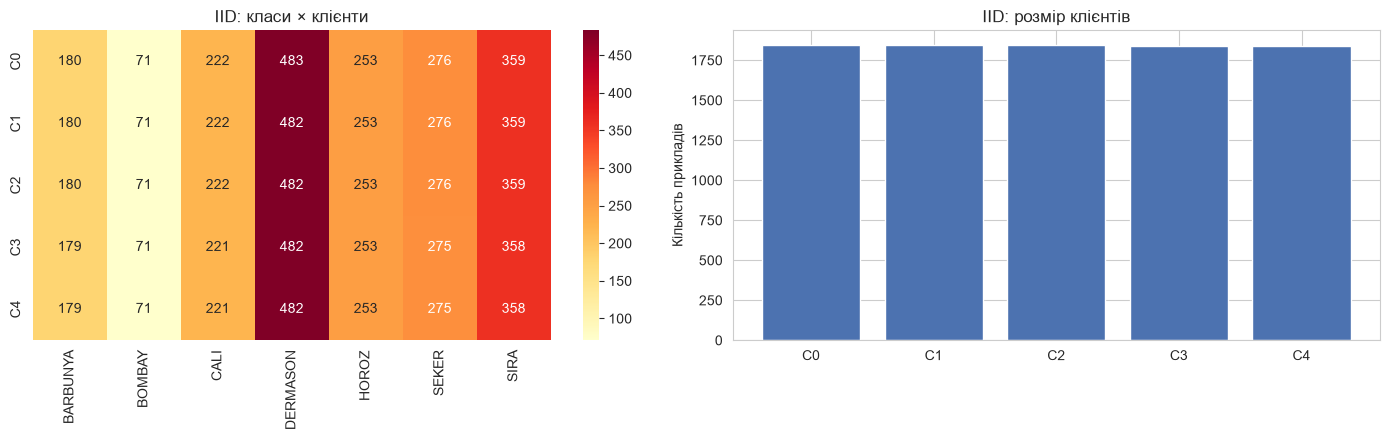

,client,n,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
0,0,1844,180,71,222,483,253,276,359
1,1,1843,180,71,222,482,253,276,359
2,2,1843,180,71,222,482,253,276,359
3,3,1839,179,71,221,482,253,275,358
4,4,1839,179,71,221,482,253,275,358



=== Dirichlet alpha=5.0 ===


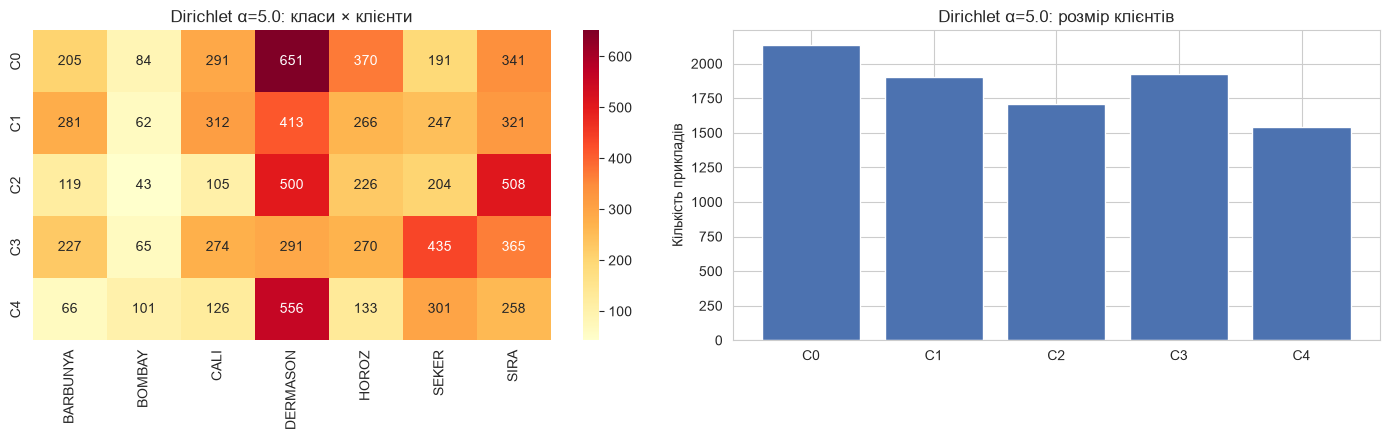

,client,n,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
0,0,2133,205,84,291,651,370,191,341
1,1,1902,281,62,312,413,266,247,321
2,2,1705,119,43,105,500,226,204,508
3,3,1927,227,65,274,291,270,435,365
4,4,1541,66,101,126,556,133,301,258



=== Dirichlet alpha=1.0 ===


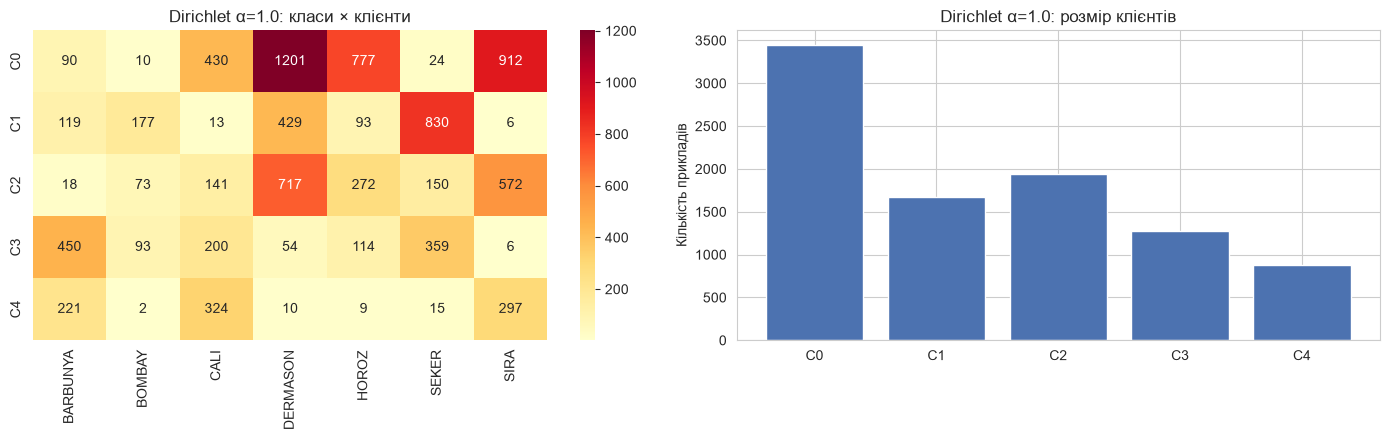

,client,n,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
0,0,3444,90,10,430,1201,777,24,912
1,1,1667,119,177,13,429,93,830,6
2,2,1943,18,73,141,717,272,150,572
3,3,1276,450,93,200,54,114,359,6
4,4,878,221,2,324,10,9,15,297



=== Dirichlet alpha=0.3 ===


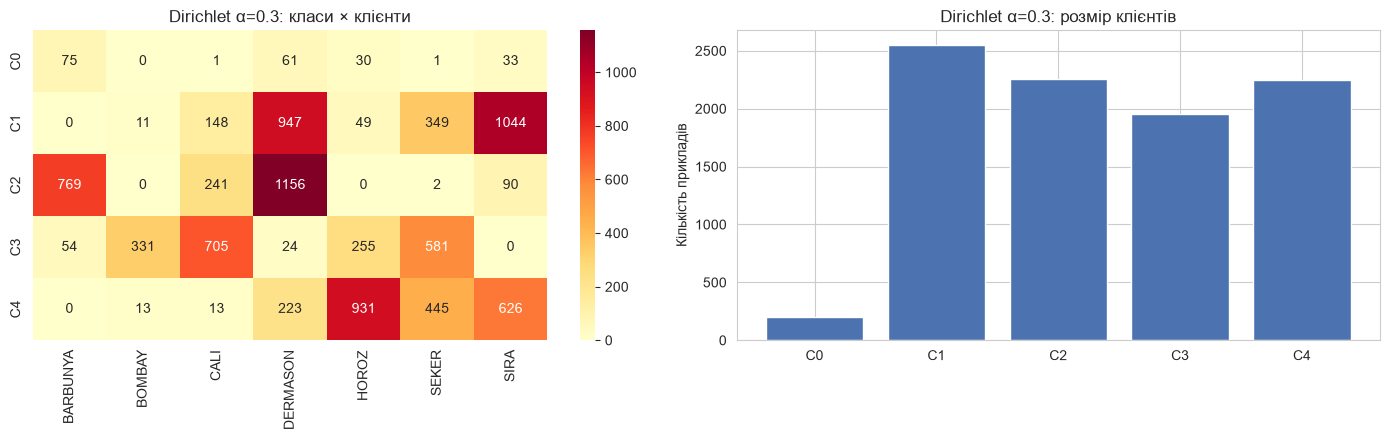

,client,n,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
0,0,201,75,0,1,61,30,1,33
1,1,2548,0,11,148,947,49,349,1044
2,2,2258,769,0,241,1156,0,2,90
3,3,1950,54,331,705,24,255,581,0
4,4,2251,0,13,13,223,931,445,626


In [14]:
def partition_iid(y: np.ndarray, n_clients: int, seed: int = 42) -> list[np.ndarray]:
    """Стратифікований IID-розподіл індексів між клієнтами."""
    rng = np.random.default_rng(seed)
    client_indices = [[] for _ in range(n_clients)]
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        splits = np.array_split(idx, n_clients)
        for k, part in enumerate(splits):
            client_indices[k].extend(part.tolist())
    return [np.array(sorted(ix), dtype=int) for ix in client_indices]


def partition_dirichlet(
    y: np.ndarray, n_clients: int, alpha: float, seed: int = 42, min_size: int = 10
) -> list[np.ndarray]:
    """Non-IID розподіл через Dirichlet(alpha) по класах."""
    rng = np.random.default_rng(seed)
    n_classes = int(y.max()) + 1
    client_indices = [[] for _ in range(n_clients)]

    for c in range(n_classes):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        proportions = rng.dirichlet(alpha=np.repeat(alpha, n_clients))
        # гарантуємо, що сума часток = 1 і розбиваємо індекси
        counts = (proportions * len(idx)).astype(int)
        # виправляємо залишок
        while counts.sum() < len(idx):
            counts[np.argmax(proportions)] += 1
        while counts.sum() > len(idx):
            j = np.argmax(counts)
            if counts[j] > 0:
                counts[j] -= 1
        start = 0
        for k, cnt in enumerate(counts):
            client_indices[k].extend(idx[start:start + cnt].tolist())
            start += cnt

    parts = [np.array(sorted(ix), dtype=int) for ix in client_indices]
    sizes = [len(p) for p in parts]
    if min(sizes) < min_size:
        print(f'Увага: є клієнт з n={min(sizes)} < {min_size} (alpha={alpha}).')
    return parts


def summarize_partition(parts, y, class_names=CLASS_NAMES, title='Розподіл'):
    rows = []
    for k, idx in enumerate(parts):
        counts = np.bincount(y[idx], minlength=len(class_names))
        row = {'client': k, 'n': len(idx), **{class_names[i]: int(counts[i]) for i in range(len(class_names))}}
        rows.append(row)
    table = pd.DataFrame(rows)
    mat = table[class_names].to_numpy()

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    sns.heatmap(mat, annot=True, fmt='d', cmap='YlOrRd',
                xticklabels=class_names, yticklabels=[f'C{k}' for k in range(len(parts))],
                ax=axes[0])
    axes[0].set_title(f'{title}: класи × клієнти')
    axes[1].bar(range(len(parts)), [len(p) for p in parts], color='#4C72B0')
    axes[1].set_xticks(range(len(parts)))
    axes[1].set_xticklabels([f'C{k}' for k in range(len(parts))])
    axes[1].set_ylabel('Кількість прикладів')
    axes[1].set_title(f'{title}: розмір клієнтів')
    plt.tight_layout()
    plt.show()
    display(table)
    return table


N_CLIENTS = 5
iid_parts = partition_iid(y_fl_enc, N_CLIENTS, seed=RANDOM_STATE)
print('=== IID ===')
iid_table = summarize_partition(iid_parts, y_fl_enc, title='IID')

dirichlet_parts = {}
for alpha in [5.0, 1.0, 0.3]:
    print(f'\n=== Dirichlet alpha={alpha} ===')
    dirichlet_parts[alpha] = partition_dirichlet(
        y_fl_enc, N_CLIENTS, alpha=alpha, seed=RANDOM_STATE, min_size=10
    )
    summarize_partition(dirichlet_parts[alpha], y_fl_enc, title=f'Dirichlet α={alpha}')


**Висновок щодо розподілу:** при великому $\alpha$ (5) розподіл близький до IID; при $\alpha=0.3$ окремі клієнти майже не бачать деяких класів. Це ускладнює FedAvg: локальні градієнти «тягнуть» глобальну модель у різні боки (**client drift**).


## Етап 5. Симуляція федеративного навчання (FedAvg)

Алгоритм:
1. Сервер ініціалізує $w_0$.
2. На раунді $t$ надсилає $w_t$ обраним клієнтам.
3. Кожен клієнт навчає локально $E$ епох, починаючи з $w_t$.
4. Сервер агрегує: $w_{t+1} = \sum_{k \in S_t} \frac{n_k}{\sum_j n_j} w_k^{t+1}$.

**Питання: чому зважувати за $n_k$?** Бо інакше клієнт з малою вибіркою матиме такий самий вплив, як клієнт з великою — оцінка глобального емпіричного ризику зміщується. Просте середнє без ваг завищує вплив малих / нетипових клієнтів.


round   8 | val_loss=0.4146 | val_acc=0.9207
round  16 | val_loss=0.3173 | val_acc=0.9317


round  24 | val_loss=0.2780 | val_acc=0.9336
round  32 | val_loss=0.2563 | val_acc=0.9348
round  40 | val_loss=0.2424 | val_acc=0.9342


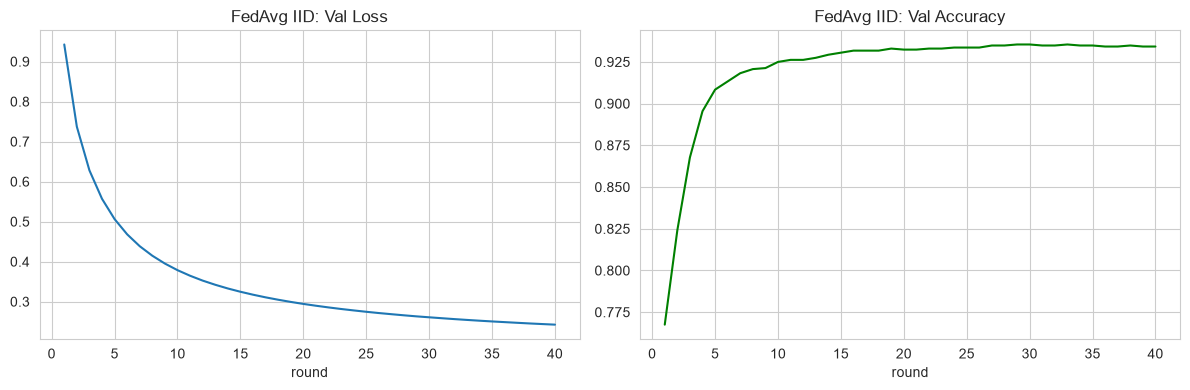

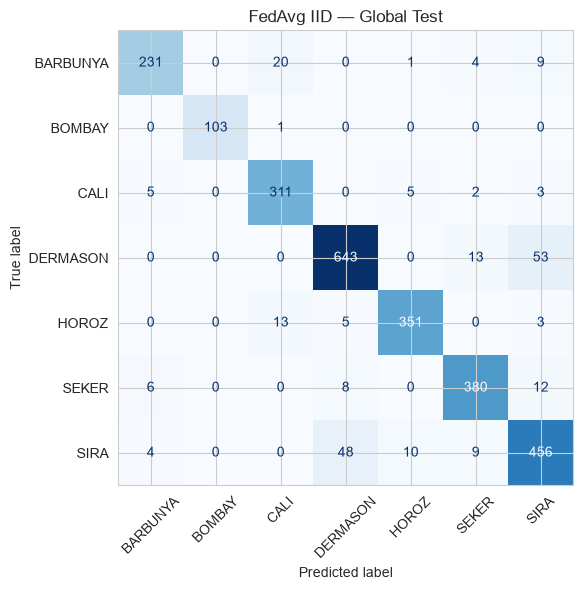

FedAvg IID @ Global Test:
  accuracy             = 0.9136
  macro_f1             = 0.9254
  balanced_accuracy    = 0.9240
  log_loss             = 0.2786


In [15]:
def fedavg(
    client_data: list[tuple[np.ndarray, np.ndarray]],
    X_val: np.ndarray,
    Y_val: np.ndarray,
    n_features: int,
    n_classes: int,
    rounds: int = 30,
    local_epochs: int = 1,
    lr: float = 0.1,
    batch_size: int = 128,
    l2: float = 1e-4,
    seed: int = 42,
    client_fraction: float = 1.0,
    verbose: bool = False,
):
    """Симуляція FedAvg. client_data: list of (X_k, Y_k one-hot)."""
    rng = np.random.default_rng(seed)
    global_model = SoftmaxLogisticRegression(n_features, n_classes, l2=l2, seed=seed)
    history = {'val_loss': [], 'val_acc': [], 'round': []}
    y_val_labels = np.argmax(Y_val, axis=1)
    n_clients = len(client_data)

    for t in range(1, rounds + 1):
        n_sel = max(1, int(np.ceil(client_fraction * n_clients)))
        selected = rng.choice(n_clients, size=n_sel, replace=False)

        W_acc = np.zeros_like(global_model.W)
        b_acc = np.zeros_like(global_model.b)
        total_n = 0.0

        gW, gb = global_model.get_params()
        for k in selected:
            Xk, Yk = client_data[k]
            local = SoftmaxLogisticRegression(n_features, n_classes, l2=l2, seed=seed + t * 100 + k)
            local.set_params(gW, gb)
            local.fit(
                Xk, Yk,
                lr=lr, batch_size=min(batch_size, len(Xk)),
                epochs=local_epochs, seed=seed + t * 100 + k, verbose=False
            )
            Wk, bk = local.get_params()
            nk = float(len(Xk))
            W_acc += nk * Wk
            b_acc += nk * bk
            total_n += nk

        global_model.set_params(W_acc / total_n, b_acc / total_n)

        val_loss = global_model.loss(X_val, Y_val)
        val_acc = float(np.mean(global_model.predict(X_val) == y_val_labels))
        history['round'].append(t)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        if verbose and (t % max(1, rounds // 5) == 0 or t == rounds):
            print(f'round {t:3d} | val_loss={val_loss:.4f} | val_acc={val_acc:.4f}')

    return global_model, history


def make_client_data(parts, X, Y):
    return [(X[idx], Y[idx]) for idx in parts]


# Базовий FedAvg на IID
client_data_iid = make_client_data(iid_parts, X_fl_s, Y_fl)
fl_iid_model, fl_iid_hist = fedavg(
    client_data_iid, X_val_s, Y_val,
    n_features=X_fl_s.shape[1], n_classes=N_CLASSES,
    rounds=40, local_epochs=1, lr=BEST_LR, batch_size=BEST_BS, l2=BEST_L2,
    seed=RANDOM_STATE, verbose=True
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(fl_iid_hist['round'], fl_iid_hist['val_loss'])
axes[0].set_title('FedAvg IID: Val Loss')
axes[0].set_xlabel('round')
axes[1].plot(fl_iid_hist['round'], fl_iid_hist['val_acc'], color='green')
axes[1].set_title('FedAvg IID: Val Accuracy')
axes[1].set_xlabel('round')
plt.tight_layout()
plt.show()

fl_iid_test = evaluate_model(fl_iid_model, X_test_s, y_test_enc, title='FedAvg IID — Global Test', plot_cm=True)
print_metrics('FedAvg IID @ Global Test', fl_iid_test)


## Етап 6. Дослідження ефектів федеративного навчання

Порівнюємо: **локальні** моделі клієнтів, **глобальну** FedAvg і **централізовану**.


In [16]:
# Локальні моделі (IID клієнти), оцінка на Global Test
local_rows = []
for k, idx in enumerate(iid_parts):
    local = SoftmaxLogisticRegression(
        X_fl_s.shape[1], N_CLASSES, l2=BEST_L2, seed=RANDOM_STATE + k
    )
    local.fit(
        X_fl_s[idx], Y_fl[idx],
        lr=BEST_LR, batch_size=BEST_BS, epochs=80, seed=RANDOM_STATE + k, verbose=False
    )
    m = evaluate_model(local, X_test_s, y_test_enc)
    local_rows.append({'model': f'local_C{k}', 'n_train': len(idx), **m})

local_df = pd.DataFrame(local_rows)
compare_df = pd.concat([
    local_df,
    pd.DataFrame([{'model': 'FedAvg_IID', 'n_train': len(X_fl_s), **fl_iid_test}]),
    pd.DataFrame([{'model': 'Centralized', 'n_train': len(X_fl_s), **central_test}]),
], ignore_index=True)

print('Порівняння на Global Test (IID клієнти):')
display(compare_df.round(4))


Порівняння на Global Test (IID клієнти):


,model,n_train,accuracy,macro_f1,balanced_accuracy,log_loss
0,local_C0,1844,0.9133,0.9253,0.9237,0.2552
1,local_C1,1843,0.9144,0.9252,0.9232,0.2575
2,local_C2,1843,0.9144,0.9263,0.9262,0.2556
3,local_C3,1839,0.9162,0.9275,0.9263,0.2510
4,local_C4,1839,0.9144,0.9253,0.9234,0.2551
5,FedAvg_IID,9208,0.9136,0.9254,0.9240,0.2786
6,Centralized,9208,0.9169,0.9281,0.9277,0.2244


### Експеримент 1. Вплив неоднорідності даних (Dirichlet α)


FedAvg Dirichlet α=5.0, E=5 @ Test:
  accuracy             = 0.9181
  macro_f1             = 0.9289
  balanced_accuracy    = 0.9276
  log_loss             = 0.2357


  mean local macro-F1=0.9245 | global macro-F1=0.9289


FedAvg Dirichlet α=1.0, E=5 @ Test:
  accuracy             = 0.9166
  macro_f1             = 0.9276
  balanced_accuracy    = 0.9243
  log_loss             = 0.2400


  mean local macro-F1=0.7358 | global macro-F1=0.9276


FedAvg Dirichlet α=0.3, E=5 @ Test:
  accuracy             = 0.9151
  macro_f1             = 0.9263
  balanced_accuracy    = 0.9236
  log_loss             = 0.2409


  mean local macro-F1=0.5789 | global macro-F1=0.9263


FedAvg IID, E=5 @ Test:
  accuracy             = 0.9173
  macro_f1             = 0.9284
  balanced_accuracy    = 0.9271
  log_loss             = 0.2358


,alpha,setting,accuracy,macro_f1,balanced_accuracy,log_loss
0,5.0,Dirichlet-5.0,0.9181,0.9289,0.9276,0.2357
1,1.0,Dirichlet-1.0,0.9166,0.9276,0.9243,0.2400
2,0.3,Dirichlet-0.3,0.9151,0.9263,0.9236,0.2409
3,inf,IID,0.9173,0.9284,0.9271,0.2358


,alpha,client,n_train,local_macro_f1,global_macro_f1
0,5.0,0,2133,0.9251,0.9289
1,5.0,1,1902,0.9276,0.9289
2,5.0,2,1705,0.9280,0.9289
3,5.0,3,1927,0.9227,0.9289
4,5.0,4,1541,0.9190,0.9289
5,1.0,0,3444,0.8635,0.9276
6,1.0,1,1667,0.6894,0.9276
7,1.0,2,1943,0.8911,0.9276
8,1.0,3,1276,0.7255,0.9276
9,1.0,4,878,0.5092,0.9276


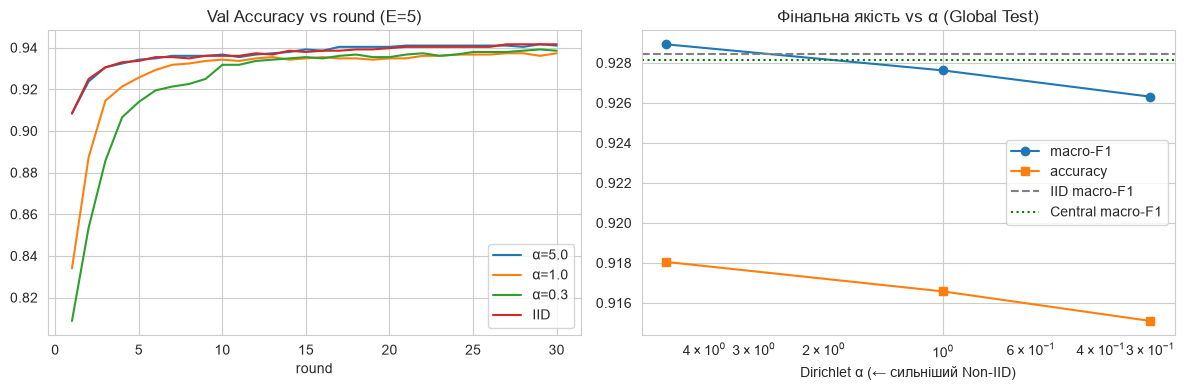

In [17]:
# E=5 підсилює client drift, тож різниця IID vs Non-IID помітніша
ALPHA_LOCAL_EPOCHS = 5
ALPHA_ROUNDS = 30

alpha_results = []
alpha_histories = {}
local_vs_global = []

for alpha in [5.0, 1.0, 0.3]:
    parts = dirichlet_parts[alpha]
    cdata = make_client_data(parts, X_fl_s, Y_fl)
    model, hist = fedavg(
        cdata, X_val_s, Y_val,
        n_features=X_fl_s.shape[1], n_classes=N_CLASSES,
        rounds=ALPHA_ROUNDS, local_epochs=ALPHA_LOCAL_EPOCHS,
        lr=BEST_LR, batch_size=BEST_BS, l2=BEST_L2,
        seed=RANDOM_STATE, verbose=False
    )
    alpha_histories[alpha] = hist
    m = evaluate_model(model, X_test_s, y_test_enc)
    alpha_results.append({'alpha': alpha, 'setting': f'Dirichlet-{alpha}', **m})
    print_metrics(f'FedAvg Dirichlet α={alpha}, E={ALPHA_LOCAL_EPOCHS} @ Test', m)

    # Середня якість локальних моделей (без агрегації) для порівняння
    local_f1 = []
    for k, idx in enumerate(parts):
        local = SoftmaxLogisticRegression(
            X_fl_s.shape[1], N_CLASSES, l2=BEST_L2, seed=RANDOM_STATE + k
        )
        local.fit(
            X_fl_s[idx], Y_fl[idx],
            lr=BEST_LR, batch_size=min(BEST_BS, len(idx)),
            epochs=80, seed=RANDOM_STATE + k, verbose=False
        )
        lm = evaluate_model(local, X_test_s, y_test_enc)
        local_f1.append(lm['macro_f1'])
        local_vs_global.append({
            'alpha': alpha, 'client': k, 'n_train': len(idx),
            'local_macro_f1': lm['macro_f1'], 'global_macro_f1': m['macro_f1']
        })
    print(f'  mean local macro-F1={np.mean(local_f1):.4f} | global macro-F1={m["macro_f1"]:.4f}')

# IID з тим самим E для чесного порівняння
fl_iid_E5_model, fl_iid_E5_hist = fedavg(
    client_data_iid, X_val_s, Y_val,
    n_features=X_fl_s.shape[1], n_classes=N_CLASSES,
    rounds=ALPHA_ROUNDS, local_epochs=ALPHA_LOCAL_EPOCHS,
    lr=BEST_LR, batch_size=BEST_BS, l2=BEST_L2,
    seed=RANDOM_STATE, verbose=False
)
fl_iid_E5_test = evaluate_model(fl_iid_E5_model, X_test_s, y_test_enc)
alpha_results.append({'alpha': np.inf, 'setting': 'IID', **fl_iid_E5_test})
alpha_histories['IID'] = fl_iid_E5_hist
print_metrics(f'FedAvg IID, E={ALPHA_LOCAL_EPOCHS} @ Test', fl_iid_E5_test)

alpha_df = pd.DataFrame(alpha_results)
display(alpha_df.round(4))
display(pd.DataFrame(local_vs_global).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for key, hist in alpha_histories.items():
    label = key if key == 'IID' else f'α={key}'
    axes[0].plot(hist['round'], hist['val_acc'], label=label)
axes[0].set_title(f'Val Accuracy vs round (E={ALPHA_LOCAL_EPOCHS})')
axes[0].set_xlabel('round')
axes[0].legend()

plot_df = alpha_df[np.isfinite(alpha_df['alpha'].astype(float))]
axes[1].plot(plot_df['alpha'], plot_df['macro_f1'], marker='o', label='macro-F1')
axes[1].plot(plot_df['alpha'], plot_df['accuracy'], marker='s', label='accuracy')
axes[1].axhline(fl_iid_E5_test['macro_f1'], color='gray', linestyle='--', label='IID macro-F1')
axes[1].axhline(central_test['macro_f1'], color='green', linestyle=':', label='Central macro-F1')
axes[1].set_xscale('log')
axes[1].invert_xaxis()
axes[1].set_xlabel('Dirichlet α (← сильніший Non-IID)')
axes[1].set_title('Фінальна якість vs α (Global Test)')
axes[1].legend()
plt.tight_layout()
plt.show()


**Пояснення (експеримент 1):**
- **Чому Non-IID погіршує FL?** Локальні оптимуми різні; усереднення ваг після локального GD дає компроміс, далекий від централізованого мінімуму. При малому α і більшому $E$ різниця стає помітнішою.
- **Чи може глобальна модель бути гіршою за централізовану?** Так — FedAvg апроксимує централізоване навчання і страждає від client drift / рідкої участі класів.
- **Чи може бути гіршою за деякі локальні?** Так: окремий клієнт із «зручним» локальним розподілом інколи має вищий score на Global Test за окремими класами, але в середньому локальні моделі на Non-IID слабші за глобальну (див. таблицю local vs global), бо не бачать усіх класів.


### Експеримент 2. Вплив кількості локальних епох E


FedAvg α=0.3, E=1 @ Test:
  accuracy             = 0.9110
  macro_f1             = 0.9226
  balanced_accuracy    = 0.9200
  log_loss             = 0.2976


FedAvg α=0.3, E=5 @ Test:
  accuracy             = 0.9151
  macro_f1             = 0.9263
  balanced_accuracy    = 0.9236
  log_loss             = 0.2409


FedAvg α=0.3, E=10 @ Test:
  accuracy             = 0.9129
  macro_f1             = 0.9238
  balanced_accuracy    = 0.9214
  log_loss             = 0.2328


,E,accuracy,macro_f1,balanced_accuracy,log_loss
0,1,0.9110,0.9226,0.9200,0.2976
1,5,0.9151,0.9263,0.9236,0.2409
2,10,0.9129,0.9238,0.9214,0.2328


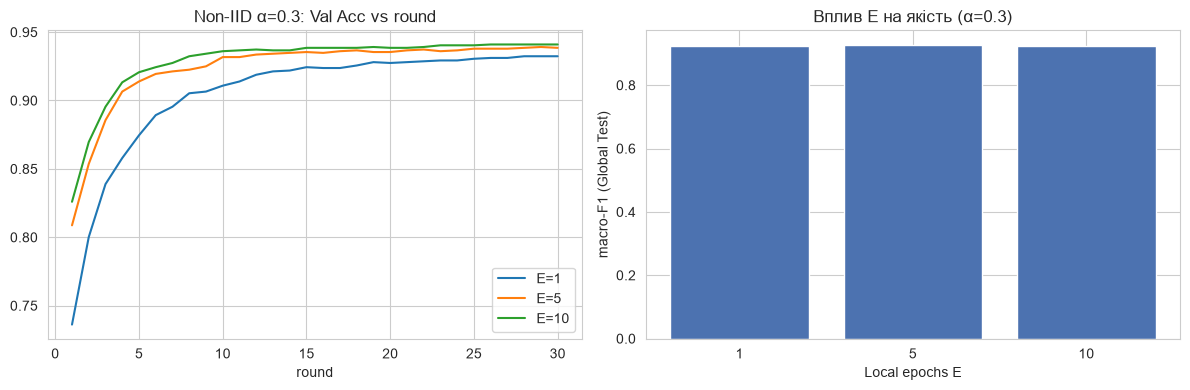

In [18]:
# Фіксуємо сильний Non-IID (α=0.3)
parts_hard = dirichlet_parts[0.3]
cdata_hard = make_client_data(parts_hard, X_fl_s, Y_fl)

E_results = []
E_histories = {}
for E in [1, 5, 10]:
    model, hist = fedavg(
        cdata_hard, X_val_s, Y_val,
        n_features=X_fl_s.shape[1], n_classes=N_CLASSES,
        rounds=30, local_epochs=E, lr=BEST_LR, batch_size=BEST_BS, l2=BEST_L2,
        seed=RANDOM_STATE, verbose=False
    )
    E_histories[E] = hist
    m = evaluate_model(model, X_test_s, y_test_enc)
    E_results.append({'E': E, **m})
    print_metrics(f'FedAvg α=0.3, E={E} @ Test', m)

E_df = pd.DataFrame(E_results)
display(E_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for E, hist in E_histories.items():
    axes[0].plot(hist['round'], hist['val_acc'], label=f'E={E}')
axes[0].set_title('Non-IID α=0.3: Val Acc vs round')
axes[0].set_xlabel('round')
axes[0].legend()
axes[1].bar([str(e) for e in E_df['E']], E_df['macro_f1'], color='#4C72B0')
axes[1].set_xlabel('Local epochs E')
axes[1].set_ylabel('macro-F1 (Global Test)')
axes[1].set_title('Вплив E на якість (α=0.3)')
plt.tight_layout()
plt.show()


**Client drift:** після багатьох локальних епох модель клієнта сильно відходить від глобальної ініціалізації раунду. На Non-IID дані локальні оновлення майже ортогональні / суперечливі; зважене усереднення дає нестабільну або гіршу глобальну модель. Тому велике $E$ економить комунікацію, але на неоднорідних даних часто шкодить.


## Теоретичні питання (відповіді)

1. **Чому softmax?** Він відображає логіти в розподіл імовірностей (сума=1, значення≥0), зручний для багатокласової класифікації.
2. **Чому cross-entropy?** Це негативна лог-правдоподібність мультиноміальної моделі; узгоджена з softmax і дає зручні градієнти $P-Y$.
3. **Ridge vs Lasso:** Ridge ($L_2$) штрафує $\|W\|_F^2$ і стискає ваги; Lasso ($L_1$) сприяє розрідженості (нульові ваги).
4. **Чому $b$ не регуляризують?** Зміщення задає базовий рівень логітів / апріорі класів; його штрафування зміщує передбачення без потреби.
5. **Data Leakage** — використання інформації з val/test (або майбутніх даних) під час навчання/препроцесингу.
6. **Test не для гіперпараметрів** — інакше «підганяємо» модель під фінальну оцінку; для цього є validation.
7. **Scaler лише на train** — інакше статистики test потрапляють у перетворення (leakage).
8. **Федеративне навчання** — спільне навчання без централізації сирих даних; переваги: приватність, менше передачі даних, відповідність регуляціям.
9. **Сервер без сирих даних** — збереження приватності та зменшення ризику витоку персональних/чутливих даних.
10. **Зважування FedAvg за $n_k$** — відповідає мінімізації глобального емпіричного ризику; більші клієнти інформативніші.
11. **Без зважування** — малі клієнти надмірно впливають, можливе зміщення та гірша узагальнююча якість.
12. **Non-IID** — локальні розподіли $P_k(x,y)$ відрізняються між клієнтами.
13. **Погіршення на Non-IID** — client drift, конфлікт оновлень, погана апроксимація централізованого градієнта.
14. **Client drift** — надмірне відхилення локальних моделей від глобальної між раундами комунікації.
15. **Вплив $E$** — більше локальних кроків → менше комунікації, але сильніший drift (особливо Non-IID).
16. **Глобальна гірша за централізовану?** Так: обмежена комунікація, неоднорідність, шум агрегації.
17. **Метрики при дисбалансі:** macro-F1, balanced accuracy (accuracy сама по собі оманлива).


## Загальний висновок

Реалізовано softmax-логістичну регресію на `numpy` і симуляцію FedAvg на Dry Bean Dataset.

- Централізована модель задає baseline і зазвичай трохи краща / порівнянна з FedAvg на IID.
- FedAvg на **IID** близький до централізованого результату.
- При зменшенні Dirichlet $\alpha$ **глобальна** модель лишається відносно стабільною (агрегація «збирає» знання з клієнтів), тоді як **локальні** моделі різко падають за macro-F1 (не бачать усіх класів) — саме в цьому головна перевага федерації над ізольованим навчанням.
- Збільшення локальних епох $E$ на Non-IID дає змішаний ефект: спочатку може покращити збіжність, далі зростає client drift і якість може погіршитись.

Коректний пайплайн (розбиття → масштабування → розподіл лише FL Train Pool → оцінка лише на Global Test) критичний, щоб уникнути Data Leakage і правильно інтерпретувати федеративні експерименти.
